In [51]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from collections import Counter

In [52]:
##Dataset Loading and Preparation
files=[
    "alice.txt",
    "pride.txt",
    "frank.txt",
    "sherlock.txt"
]
books=[]
for file in files:
  with open(file,"r",encoding="utf-8") as f:
    text=f.read()
    books.append(text)
  print(file,"loaded successfully")

alice.txt loaded successfully
pride.txt loaded successfully
frank.txt loaded successfully
sherlock.txt loaded successfully


In [53]:
corpus=" ".join(books)
print("Dataset combined successfully")
print("Total characters:",len(corpus))
total_words=len(corpus.split())
print("Total words in dataset:",total_words)

Dataset combined successfully
Total characters: 1932562
Total words in dataset: 345649


In [54]:
### Identifying Unnecessary Text
for filename,text in zip(files,books):
  print("\nBook:",filename)
  start=text.find("*** START OF")
  end=text.find("*** END OF")
  print("Start marker found:",start!=-1)
  print("End marker found:",end!=-1)


Book: alice.txt
Start marker found: True
End marker found: True

Book: pride.txt
Start marker found: True
End marker found: True

Book: frank.txt
Start marker found: True
End marker found: True

Book: sherlock.txt
Start marker found: True
End marker found: True


In [55]:
### Extracting Actual Book Content
cleaned_books=[]
for text in books:
  start=text.find("*** START OF")
  end=text.find("*** END OF")
  start = text.find("\n", start) + 1
  book_content=text[start:end]
  cleaned_books.append(book_content)
print("headers and footers removed")

headers and footers removed


In [56]:
### Combine all cleaned books into one corpus
cleaned_corpus=" ".join(cleaned_books)
print("Total characters:", len(cleaned_corpus))
print("Total words:", len(cleaned_corpus.split()))

Total characters: 1854912
Total words: 333433


In [57]:
### Text Tokenization
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
tokens=word_tokenize(cleaned_corpus)
print("Total tokens:",len(tokens))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Total tokens: 396108


In [58]:
### Lowercase Conversion
lower_tokens = [word.lower() for word in tokens]

In [59]:
### Punctuation and Stopword Removal
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
autocomplete_tokens = []
for word in lower_tokens:
    if word.isalpha():
        autocomplete_tokens.append(word)
clean_tokens = []
for word in autocomplete_tokens:
    if word not in stop_words and word.isalpha():
        clean_tokens.append(word)
print("Autocomplete tokens:", len(autocomplete_tokens))
print("Clean tokens:", len(clean_tokens))
print("Sample clean tokens:", clean_tokens[:20])

Autocomplete tokens: 328418
Clean tokens: 144975
Sample clean tokens: ['illustration', 'alice', 'adventures', 'wonderland', 'lewis', 'carroll', 'millennium', 'fulcrum', 'edition', 'contents', 'chapter', 'chapter', 'ii', 'pool', 'tears', 'chapter', 'iii', 'long', 'tale', 'chapter']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [60]:
word_counts = Counter(clean_tokens)
print("Most common 10 words:")
print(word_counts.most_common(10))


Most common 10 words:
[('said', 1450), ('could', 1085), ('would', 1069), ('one', 949), ('elizabeth', 732), ('upon', 687), ('little', 640), ('man', 589), ('must', 577), ('much', 543)]


In [61]:
###Bigram creation and calculating bigram frequencies
bigrams=[]
for i in range(len(autocomplete_tokens)-1):
  bigrams.append((autocomplete_tokens[i],autocomplete_tokens[i+1]))
print("Total bigrams:",len(bigrams))
bigram_counts=Counter(bigrams)
print("Top 10 bigrams:",bigram_counts.most_common(10))

Total bigrams: 328417
Top 10 bigrams: [(('of', 'the'), 1880), (('in', 'the'), 1268), (('to', 'the'), 834), (('to', 'be'), 785), (('it', 'was'), 739), (('and', 'the'), 650), (('it', 'is'), 620), (('i', 'am'), 612), (('i', 'have'), 603), (('that', 'i'), 572)]


In [62]:
###Bigram Prediction Dictionary
bigram_model = {}
for (word1, word2), count in bigram_counts.items():
    if word1 not in bigram_model:
        bigram_model[word1] = []
    bigram_model[word1].append((word2, count))
print("Bigram prediction dictionary created!")

Bigram prediction dictionary created!


In [63]:
###Sort Bigram Predictions by Frequency
for word in bigram_model:
    bigram_model[word] = sorted(bigram_model[word], key=lambda x: x[1], reverse=True)
print("Top predictions for 'alice':", bigram_model.get('alice', [])[:10])

Top predictions for 'alice': [('and', 20), ('was', 17), ('i', 15), ('s', 14), ('had', 12), ('as', 12), ('thought', 12), ('said', 11), ('could', 11), ('did', 10)]


In [64]:
###Create the Bigram Autocomplete Function
def autocomplete(word):
    word = word.lower()
    predictions = bigram_model.get(word, [])
    return predictions[:3]
print("Predictions for 'sherlock':", autocomplete("sherlock"))

Predictions for 'sherlock': [('holmes', 95), ('there', 1), ('james', 1)]


In [65]:
###Test Bigram Autocomplete with 10 Inputs
test_words = ['alice', 'sherlock', 'elizabeth', 'darcy', 'holmes',
              'wonderland', 'frankenstein', 'said', 'mr', 'little']
for word in test_words:
    print(word, "->", autocomplete(word))

alice -> [('and', 20), ('was', 17), ('i', 15)]
sherlock -> [('holmes', 95), ('there', 1), ('james', 1)]
elizabeth -> [('was', 67), ('s', 44), ('had', 40)]
darcy -> [('s', 46), ('and', 23), ('was', 23)]
holmes -> [('i', 31), ('and', 24), ('had', 16)]
wonderland -> [('by', 1), ('though', 1), ('of', 1)]
frankenstein -> [('exclaimed', 2), ('my', 2), ('your', 2)]
said -> [('the', 237), ('he', 194), ('alice', 116)]
mr -> [('darcy', 10), ('collins', 3), ('spectator', 1)]
little -> [('of', 23), ('more', 15), ('to', 12)]


In [66]:
!pip install pyspellchecker

In [67]:
# Import and Initialize the Spell Checker
from spellchecker import SpellChecker
spell = SpellChecker()
spell.word_frequency.load_words(autocomplete_tokens)
test_names = ["elizabeth", "sherlock", "holmes", "darcy", "frankenstein"]
for word in test_names:
    print(word, "->", spell.correction(word))

elizabeth -> elizabeth
sherlock -> sherlock
holmes -> holmes
darcy -> darcy
frankenstein -> frankenstein


In [68]:
###Test Autocorrect with 20 Misspelled Words
misspelled_words = [
    "helo", "recieve", "becaus", "frend", "beautifull",
    "acheive", "adress", "begining", "belive", "definately",
    "enviroment", "goverment", "happend", "knowlege", "occured",
    "seperate", "tommorow", "writting", "thier", "untill"
]
for word in misspelled_words:
    print(word, "->", spell.correction(word))

helo -> help
recieve -> receive
becaus -> because
frend -> friend
beautifull -> beautiful
acheive -> achieve
adress -> dress
begining -> beginning
belive -> believe
definately -> definitely
enviroment -> environment
goverment -> government
happend -> happened
knowlege -> knowledge
occured -> occurred
seperate -> separate
tommorow -> tomorrow
writting -> writing
thier -> their
untill -> until


In [69]:
# Step 6: Calculate Autocorrect Accuracy
correct_words = [
    "hello", "receive", "because", "friend", "beautiful",
    "achieve", "address", "beginning", "believe", "definitely",
    "environment", "government", "happened", "knowledge", "occurred",
    "separate", "tomorrow", "writing", "their", "until"
]
predictions = [spell.correction(word) for word in misspelled_words]
correct_count = 0
for predicted, expected in zip(predictions, correct_words):
    if predicted == expected:
        correct_count += 1
accuracy = (correct_count / len(correct_words)) * 100
print("Correct corrections:", correct_count)
print("Total words tested:", len(correct_words))
print("Autocorrect accuracy:", accuracy, "%")

Correct corrections: 18
Total words tested: 20
Autocorrect accuracy: 90.0 %


In [70]:
###Calculate Autocorrect Precision and Recall

true_positive = 0
false_positive = 0
false_negative = 0
for predicted, expected in zip(predictions, correct_words):
    if predicted == expected:
        true_positive += 1
    else:
        false_positive += 1
        false_negative += 1
precision = true_positive / (true_positive + false_positive) * 100
recall = true_positive / (true_positive + false_negative) * 100
print("Precision:", precision, "%")
print("Recall:", recall, "%")

Precision: 90.0 %
Recall: 90.0 %


In [71]:
###Calculate Autocomplete Precision and Recall

true_positive = 0
false_positive = 0
false_negative = 0
total = 0
for i in range(len(autocomplete_tokens) - 1):
    word = autocomplete_tokens[i]
    actual_word = autocomplete_tokens[i + 1]
    predictions = autocomplete(word)
    if predictions:
      total += 1
      predicted_words = [item[0] for item in predictions]
      if actual_word in predicted_words:
        true_positive += 1
        false_positive += len(predicted_words) - 1
      else:
        false_positive += len(predicted_words)
        false_negative += 1
precision = true_positive / (true_positive + false_positive) * 100
recall = true_positive / (true_positive + false_negative) * 100
accuracy = (true_positive / total) * 100
print("Precision:", precision, "%")
print("Recall:", recall, "%")
print("Top-3 Accuracy:", accuracy, "%")

Precision: 10.720515381191436 %
Recall: 31.607986188291104 %
Top-3 Accuracy: 31.607986188291104 %


In [72]:
###Compare Two Autocorrect Approaches

default_spell = SpellChecker()
default_correct = 0
dataset_correct = 0
for i in range(len(misspelled_words)):
    word = misspelled_words[i]
    default_prediction = default_spell.correction(word)
    dataset_prediction = spell.correction(word)
    if default_prediction == correct_words[i]:
      default_correct += 1
    if dataset_prediction == correct_words[i]:
      dataset_correct += 1
    print(word, "-> Default:", default_prediction, "| Dataset:", dataset_prediction)
default_accuracy = (default_correct / len(correct_words)) * 100
dataset_accuracy = (dataset_correct / len(correct_words)) * 100
print("\nDefault Spell Checker Accuracy:", default_accuracy, "%")
print("Dataset-Enhanced Spell Checker Accuracy:", dataset_accuracy, "%")

helo -> Default: help | Dataset: help
recieve -> Default: receive | Dataset: receive
becaus -> Default: because | Dataset: because
frend -> Default: friend | Dataset: friend
beautifull -> Default: beautiful | Dataset: beautiful
acheive -> Default: achieve | Dataset: achieve
adress -> Default: dress | Dataset: dress
begining -> Default: beginning | Dataset: beginning
belive -> Default: believe | Dataset: believe
definately -> Default: definitely | Dataset: definitely
enviroment -> Default: environment | Dataset: environment
goverment -> Default: government | Dataset: government
happend -> Default: happened | Dataset: happened
knowlege -> Default: knowledge | Dataset: knowledge
occured -> Default: occurred | Dataset: occurred
seperate -> Default: separate | Dataset: separate
tommorow -> Default: tomorrow | Dataset: tomorrow
writting -> Default: writing | Dataset: writing
thier -> Default: their | Dataset: their
untill -> Default: until | Dataset: until

Default Spell Checker Accuracy: 90

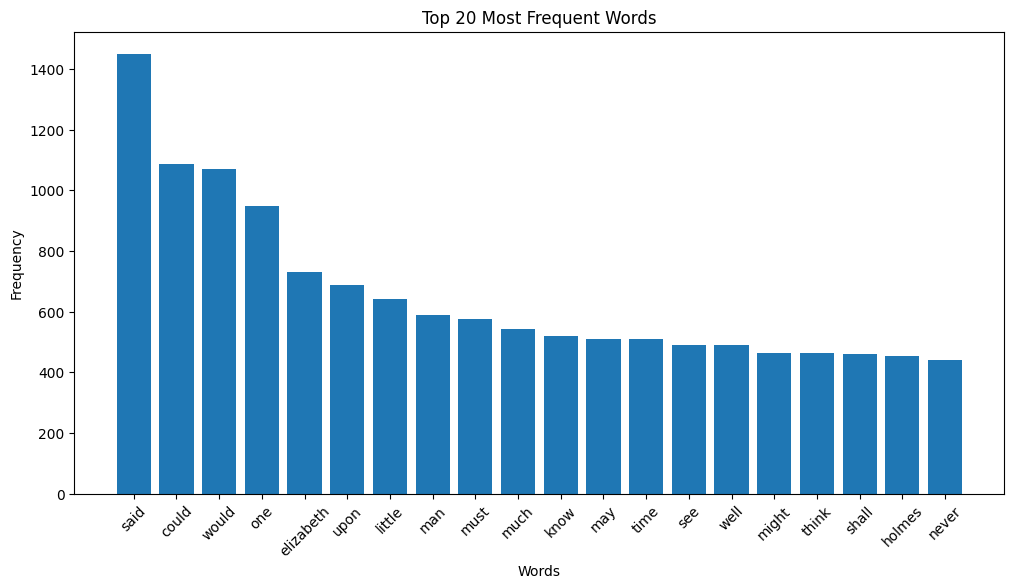

In [73]:
###Visualize Top 20 Frequent Words
top_words = word_counts.most_common(20)
words = [word[0] for word in top_words]
counts = [word[1] for word in top_words]
plt.figure(figsize=(12, 6))
plt.bar(words, counts)
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Top 20 Most Frequent Words")
plt.xticks(rotation=45)
plt.show()

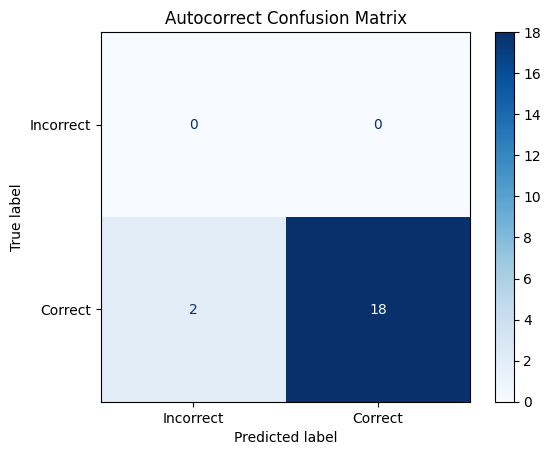

In [74]:
###Autocorrect Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
autocorrect_predictions = [spell.correction(word) for word in misspelled_words]
actual = [1] * len(correct_words)
predicted = [1 if p == c else 0 for p, c in zip(autocorrect_predictions, correct_words)]
cm = confusion_matrix(actual, predicted, labels=[0, 1])
display = ConfusionMatrixDisplay(cm, display_labels=["Incorrect", "Correct"])
display.plot(cmap="Blues")
plt.title("Autocorrect Confusion Matrix")
plt.show()

Limitations
- Our model is trained on only four books, so its vocabulary is limited.
- Bigram autocomplete considers only the previous word, not the full sentence.
- Autocorrect sometimes suggests the wrong word.
- Unlike Google Keyboard, our project does not learn from user typing habits.
Conclusion: This project helped me understand the basic working of autocomplete and autocorrect using NLP techniques.